# CatDSGE for India: estimation

The CatDSGE model fit to Indian data, under the priors of `02_catdsge_prior_analysis.ipynb`: the observables, the posterior mode, NUTS from the mode, sampling diagnostics, the posterior against the priors and the published estimates, and checks of the solved model across the posterior draws.

In [1]:
import dataclasses

from itertools import product
from pathlib import Path

import arviz as az
import jax
import matplotlib.pyplot as plt
import numpy as np
import nutpie as ntp
import pandas as pd
import preliz as pz
import pymc as pm
import pymc_extras as pmx
import xarray as xr

from IPython.display import display
from tqdm.auto import tqdm

import gEconpy as ge

from gEconpy.plotting import plot_acf, plot_eigenvalues, plot_posterior_with_prior

from catdsge import (build_observed,
                     build_pymc_model,
                     calibrate_india,
                     compute_data_targets,
                     configure_session,
                     fixed_parameters,
                     load_estimation_statespace,
                     median_and_hdi,
                     model_ratios,
                     noise_sd_scales,
                     plot_density_against_data,
                     plot_estimate,
                     plot_moment_grid,
                     statespace_trace,
                     to_display_units)
from climate_risk.dsge.model_files import GCN_DIR
from climate_risk.plotting import PALETTE

configure_session()
data_dir = Path("data")

In [2]:
model = ge.model_from_gcn(GCN_DIR / "catdsge_v4.gcn")
panel = pd.read_parquet(data_dir / "india_mixed_frequency.parquet")
panel.index = panel.index.to_period("Q")

data_targets = compute_data_targets(panel)
india_parameters = calibrate_india(model, panel)
india_model_parameters = model.parameters(**india_parameters)
india_steady_state = model.steady_state(verbose=False,
                                        progressbar=False,
                                        **india_parameters)

In [3]:
statespace = load_estimation_statespace()
estimated_shocks = list(statespace.shock_names)

observed = build_observed(panel)
fit_data = observed.set_axis(observed.index.to_timestamp())
pymc_model = build_pymc_model(statespace=statespace,
                              fit_data=fit_data,
                              model_parameters=india_model_parameters)

## 1. Data

The log-linearized model is fit over 2012Q1 to 2024Q4 to quarterly growth of GDP, consumption, investment, exports and imports, CPI inflation, and real depreciation of the rupee. Four foreign series pin down the rest-of-world block, all of them US or world aggregates: the US 3-month rate for the foreign interest rate, US CPI inflation for foreign inflation, quarterly growth of US real GDP for foreign output, and real growth of the broad commodity price index for the world import price. Government debt and tax revenue enter as annual ratios to GDP. The lockdown quarters 2020Q1 to 2021Q4 are treated as missing.

In [ ]:
(100 * observed).describe().T[["count", "mean", "std"]]

The real exchange rate is the BIS broad real effective exchange rate of the rupee, against 64 economies, averaged to quarters. A rise in the index is a real appreciation of the rupee, the opposite direction to the model's $q_t$, so the observable is minus its log change.

In [ ]:
window_dates = observed.index.to_timestamp()

fig, axes = plt.subplots(ncols=2,
                         figsize=(13, 3.5),
                         layout="constrained")
axes[0].plot(window_dates,
             panel["real_effective_exchange_rate"].loc[observed.index],
             color="k",
             lw=1.2)
axes[0].set_title("BIS real effective exchange rate, index 2020 = 100", loc="left")
axes[1].plot(window_dates,
             100 * observed["real_exchange_rate_growth"],
             color="k",
             lw=1.2)
axes[1].axhline(0.0, color="0.6", lw=0.8)
axes[1].set_title("Real depreciation, demeaned quarterly log change (%)", loc="left");

## 2. Posterior mode

The sampler starts from the posterior mode, found with L-BFGS-B on JAX-compiled gradients.

In [4]:
with pymc_model:
    map_result = pmx.find_MAP(method="L-BFGS-B",
                              gradient_backend="jax",
                              compile_kwargs={"mode": "JAX"},
                              random_seed=20261014)

map_estimate = map_result.posterior.to_dataset().squeeze(["chain", "draw"], drop=True)
optimizer_result = map_result["optimizer_result"]
pd.Series({"converged": bool(optimizer_result["success"]),
           "message": str(optimizer_result["message"].values),
           "iterations": int(optimizer_result["nit"]),
           "log posterior": -float(optimizer_result["fun"]),
           "max |gradient|": float(np.abs(optimizer_result["jac"]).max())},
          name="L-BFGS-B").to_frame()

Output()

,L-BFGS-B
converged,True
message,CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*...
iterations,85
log posterior,1494.22
max |gradient|,0.01


## 3. NUTS from the MAP

Eight chains start from the MAP plus Gaussian noise with standard deviation 0.1 in the unconstrained space, and run 500 tuning and 250 posterior draws each with nutpie's normalizing-flow adaptation. The transform is refit every 16 tuning draws: the first four refits are diagonal, and every refit after draw 64 trains a flow of 4 coupling layers with SiLU activations on the leapfrog points of the recent trajectories. The trace is saved after sampling and reloaded in the next cell, so every section after it can be rerun from the saved trace without sampling again.

In [5]:
map_initial_point = {variable.name: map_estimate[variable.name].values for variable in pymc_model.free_RVs}
map_nutpie_model = ntp.compile_pymc_model(pymc_model,
                                          backend="jax",
                                          gradient_backend="jax",
                                          freeze_model=True,
                                          initial_points=map_initial_point,
                                          jitter_rvs=set())
map_flat = map_nutpie_model._make_initial_points(0)


def jittered_map_point(seed):
    return map_flat + 0.1 * np.random.default_rng(seed).normal(size=map_flat.shape)


# nutpie's own jitter is fixed at U(-1, 1), so the initial-point function is replaced on the frozen dataclass.
jittered_nutpie_model = dataclasses.replace(map_nutpie_model, _make_initial_points=jittered_map_point)

In [6]:
FLOW_ADAPTER_SETTINGS = {"num_diag_windows": 4,
                         "num_layers": 4,
                         "activation": jax.nn.silu,
                         "window_size": 3000,
                         "initial_skip": 500,
                         "max_epochs": 50,
                         "max_patience": 5}

flow_nutpie_model = jittered_nutpie_model.with_transform_adapt(**FLOW_ADAPTER_SETTINGS)
map_init_idata = ntp.sample(flow_nutpie_model,
                            chains=8,
                            cores=8,
                            tune=500,
                            draws=250,
                            adaptation="flow",
                            window_switch_freq=16,
                            train_on_orbit=True,
                            seed=20261014,
                            progress_bar=True)

Progress,Draws,Divergences,Step Size,Gradients/Draw
,750,1,0.34,15
,750,6,0.42,15
,750,0,0.39,15
,750,0,0.36,15
,750,23,0.36,15
,750,2,0.41,15
,750,0,0.41,15
,750,6,0.37,2


In [7]:
map_init_idata.to_netcdf(data_dir / "catdsge_flow_tight_shocks_idata.nc")

In [8]:
with xr.open_datatree(data_dir / "catdsge_flow_tight_shocks_idata.nc") as saved_trace:
    map_init_idata = saved_trace.load()

## 4. Sampling checks

Divergences per chain and the parameters with the largest $\hat R$, then the energy distribution of the Hamiltonian transitions.

In [9]:
map_init_diagnostics = az.summary(map_init_idata, kind="diagnostics")
map_init_divergences = map_init_idata.sample_stats["diverging"].sum("draw").to_series()

display(map_init_divergences.rename("post-warmup divergences").to_frame().T)
map_init_diagnostics.sort_values("r_hat", ascending=False).head(15)

/Users/jessegrabowski/mambaforge/envs/climate-risk/lib/python3.12/site-packages/arviz_stats/base/diagnostics.py:90: RuntimeWarning: invalid value encountered in scalar divide
  (between_chain_variance / within_chain_variance + num_samples - 1) / (num_samples)
/Users/jessegrabowski/mambaforge/envs/climate-risk/lib/python3.12/site-packages/arviz_stats/base/diagnostics.py:313: RuntimeWarning: invalid value encountered in scalar divide
  varsd = varvar / evar / 4
/Users/jessegrabowski/mambaforge/envs/climate-risk/lib/python3.12/site-packages/arviz_stats/base/diagnostics.py:313: RuntimeWarning: invalid value encountered in scalar divide
  varsd = varvar / evar / 4
/Users/jessegrabowski/mambaforge/envs/climate-risk/lib/python3.12/site-packages/arviz_stats/base/diagnostics.py:313: RuntimeWarning: invalid value encountered in scalar divide
  varsd = varvar / evar / 4
/Users/jessegrabowski/mambaforge/envs/climate-risk/lib/python3.12/site-packages/arviz_stats/base/diagnostics.py:313: RuntimeWarn

chain,0,1,2,3,4,5,6,7
post-warmup divergences,1,6,0,0,23,2,0,6


,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
shock_cov[104],243,68,1.04,0.45,0.71
shock_cov[92],1050,229,1.04,0.067,0.2
shock_cov_stds[13],244,68,1.04,0.61,0.91
sigma_epsilon_xi_M,244,68,1.04,0.0015,0.0023
"state_cov[epsilon_xi_M, epsilon_xi_M]",244,68,1.04,8.5e-05,0.00014
shock_cov[94],868,319,1.03,0.053,0.24
"state_cov[epsilon_xi_M, epsilon_beta]",748,336,1.03,2.3e-07,9e-07
"state_cov[epsilon_beta, epsilon_xi_M]",748,336,1.03,2.3e-07,9e-07
shock_cov[102],1332,135,1.03,0.067,0.21
error_sigma_pi,279,112,1.03,9.5e-05,0.00014


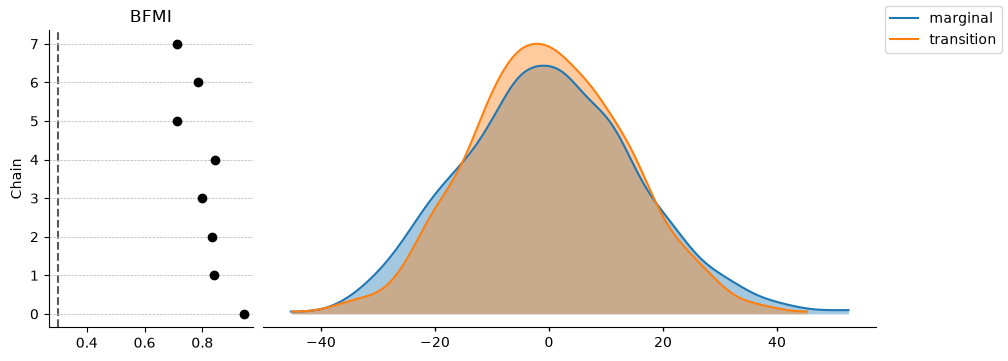

In [10]:
az.plot_energy(map_init_idata,
               figure_kwargs={"figsize": (10, 3.5)});

## 5. Posterior

Posterior summaries of the structural parameters next to the MAP and the published estimates, then each marginal posterior against its prior.

In [11]:
STRUCTURAL_PRIORS = {"phi_H": ("Beta", 0.30, 0.15),
                     "chi": ("Gamma", 2.0, 1.0),
                     "psi_z": ("Gamma", 0.20, 0.15),
                     "gamma_I": ("Gamma", 5.0, 2.0),
                     "theta_H": ("Beta", 0.63, 0.10),
                     "gamma_H": ("Beta", 0.20, 0.10),
                     "phi_pi": ("Gamma", 1.5, 0.25),
                     "phi_y": ("Gamma", 0.125, 0.05),
                     "rho_i": ("Beta", 0.85, 0.05),
                     "phi_debt": ("Gamma", 0.083, 0.039)}
# The Beta prior on theta_w that the prior on the log wage Phillips-curve slope was matched to.
WAGE_CALVO_PRIOR = {"mu": 0.75, "sigma": 0.05}
ESTIMATED_STRUCTURAL = [*STRUCTURAL_PRIORS, "theta_w"]
SHOCK_SCALE_ALPHA = 3.0
SHOCK_SCALE_MODES = {"epsilon_A": 0.0021,
                     "epsilon_beta": 0.0009,
                     "epsilon_xi_I": 0.003,
                     "epsilon_xi_H": 0.0025,
                     "epsilon_xi_w": 0.0025,
                     "epsilon_q": 0.013,
                     "epsilon_p_M_star": 0.042,
                     "epsilon_Y_star": 0.0018,
                     "epsilon_pi_star": 0.0012,
                     "epsilon_i_star": 0.001,
                     "epsilon_i": 0.000375,
                     "epsilon_G": 0.0045,
                     "epsilon_tau_L": 0.00045,
                     "epsilon_tau_M": 0.00045,
                     "epsilon_xi_M": 0.0025,
                     "epsilon_xi_X": 0.0025,
                     "epsilon_xi_XD": 0.006}

SOURCES = ["Sharma and Behera (2022)", "Sachdeva and Ahmad (2024)"]
PARAMETER_LABELS = {"phi_H": r"habit $\phi_H$",
                    "chi": r"inverse Frisch $\chi$",
                    "alpha": r"capital share $\alpha$",
                    "theta_H": r"price Calvo $\theta_H$",
                    "gamma_H": r"price indexation $\gamma_H$",
                    "theta_w": r"wage Calvo $\theta_w$",
                    "phi_pi": r"Taylor inflation $\phi_\pi$",
                    "phi_y": r"Taylor output $\phi_y$",
                    "rho_i": r"rate smoothing $\rho_i$"}
literature = pd.DataFrame([("phi_H", SOURCES[0], 0.13, 0.04, 0.22, "estimated"),
                           ("phi_H", SOURCES[1], 0.47, 0.33, 0.63, "estimated"),
                           ("chi", SOURCES[0], 2.70, 1.08, 4.28, "estimated"),
                           ("chi", SOURCES[1], 1.01, 0.84, 1.16, "prior-dominated"),
                           ("alpha", SOURCES[0], 0.36, 0.27, 0.45, "estimated"),
                           ("alpha", SOURCES[1], 0.33, np.nan, np.nan, "fixed"),
                           ("theta_H", SOURCES[0], 0.63, 0.55, 0.71, "estimated"),
                           ("theta_H", SOURCES[1], 0.75, np.nan, np.nan, "fixed"),
                           ("gamma_H", SOURCES[0], 0.20, 0.08, 0.32, "estimated"),
                           ("gamma_H", SOURCES[1], 0.10, np.nan, np.nan, "fixed"),
                           ("theta_w", SOURCES[0], 0.00, np.nan, np.nan, "fixed"),
                           ("theta_w", SOURCES[1], 0.75, np.nan, np.nan, "fixed"),
                           ("phi_pi", SOURCES[0], 1.55, 1.42, 1.67, "prior-dominated"),
                           ("phi_pi", SOURCES[1], 1.44, 1.02, 1.72, "estimated"),
                           ("phi_y", SOURCES[0], 0.68, 0.46, 0.90, "estimated"),
                           ("phi_y", SOURCES[1], -0.01, -0.01, 0.00, "estimated"),
                           ("rho_i", SOURCES[0], 0.81, 0.77, 0.85, "estimated"),
                           ("rho_i", SOURCES[1], 0.92, 0.90, 0.94, "estimated")],
                          columns=["parameter", "source", "value", "lower", "upper", "status"])

In [12]:
published_values = literature.pivot(index="parameter", columns="source", values="value")
prior_means = pd.Series({**{name: mean for name, (_, mean, _) in STRUCTURAL_PRIORS.items()},
                         "theta_w": WAGE_CALVO_PRIOR["mu"]})
map_values = pd.Series({name: float(map_estimate[name]) for name in ESTIMATED_STRUCTURAL})

posterior_summary = az.summary(map_init_idata,
                               var_names=ESTIMATED_STRUCTURAL,
                               kind="stats")
posterior_summary.insert(loc=0,
                         column="prior mean",
                         value=prior_means)
posterior_summary.insert(loc=1,
                         column="MAP",
                         value=map_values)
posterior_summary.join(published_values).style.format("{:.3f}", na_rep="")

,prior mean,MAP,mean,sd,eti89_lb,eti89_ub,Sachdeva and Ahmad (2024),Sharma and Behera (2022)
phi_H,0.300,0.075,0.145,0.081,0.042,0.288,0.470,0.130
chi,2.000,1.702,1.846,0.850,0.686,3.310,1.010,2.700
psi_z,0.200,0.080,0.227,0.149,0.052,0.518,,
gamma_I,5.000,3.610,5.570,1.932,2.980,8.897,,
theta_H,0.630,0.640,0.652,0.089,0.498,0.782,0.750,0.630
gamma_H,0.200,0.178,0.224,0.110,0.073,0.420,0.100,0.200
phi_pi,1.500,1.160,1.663,0.240,1.301,2.075,1.440,1.550
phi_y,0.125,0.060,0.090,0.034,0.043,0.147,-0.010,0.680
rho_i,0.850,0.917,0.866,0.050,0.779,0.935,0.920,0.810
phi_debt,0.083,0.032,0.053,0.019,0.025,0.086,,


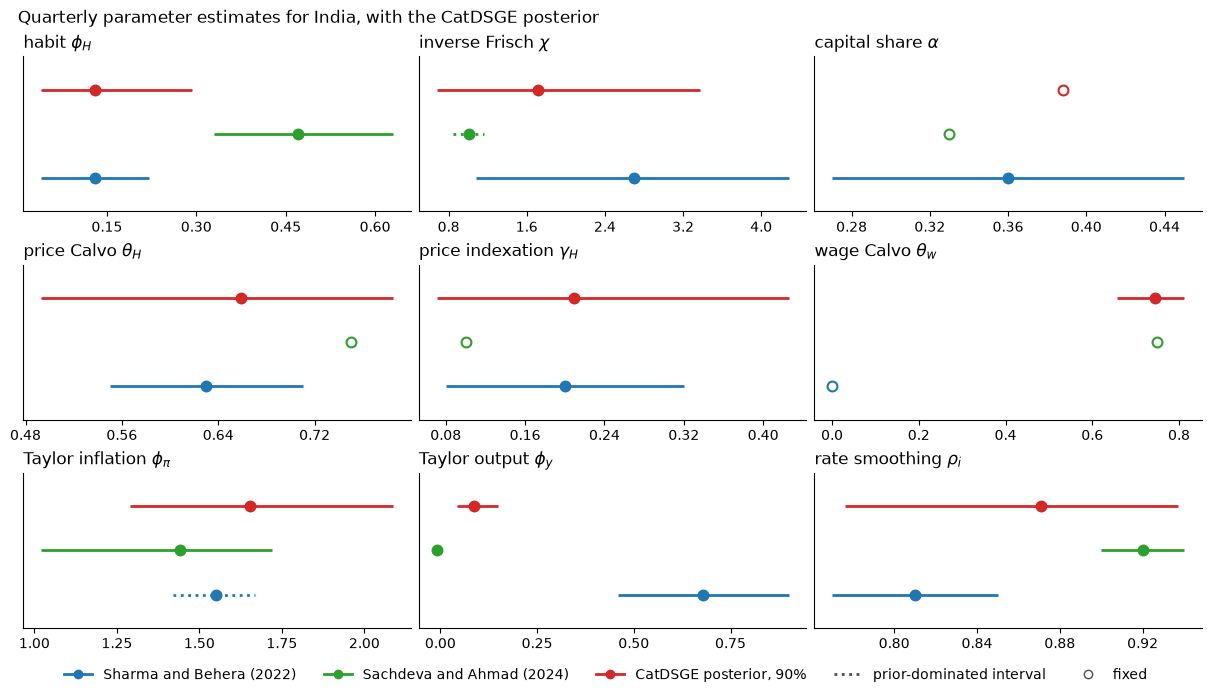

In [13]:
CATDSGE_COLOR = PALETTE["secondary"]
SOURCE_COLORS = dict(zip(SOURCES, [PALETTE["primary"], "tab:green"], strict=True))

posterior_quantiles = map_init_idata.posterior.to_dataset()[ESTIMATED_STRUCTURAL].quantile([0.05, 0.5, 0.95],
                                                                                           dim=["chain", "draw"])

fig, axes = plt.subplots(nrows=3,
                         ncols=3,
                         figsize=(12, 6.5),
                         layout="constrained")
for ax, (parameter, label) in zip(axes.flat, PARAMETER_LABELS.items(), strict=True):
    estimates = literature[literature["parameter"] == parameter]
    for y_position, row in enumerate(estimates.itertuples()):
        plot_estimate(ax=ax, row=row, y_position=y_position)

    catdsge_position = len(estimates)
    if parameter in ESTIMATED_STRUCTURAL:
        quantiles = posterior_quantiles[parameter]
        ax.hlines(y=catdsge_position,
                  xmin=float(quantiles.sel(quantile=0.05)),
                  xmax=float(quantiles.sel(quantile=0.95)),
                  color=CATDSGE_COLOR,
                  lw=2.0)
        ax.scatter(x=float(quantiles.sel(quantile=0.5)),
                   y=catdsge_position,
                   s=50,
                   color=CATDSGE_COLOR,
                   edgecolor=CATDSGE_COLOR,
                   linewidth=1.5,
                   zorder=3)
    else:
        ax.scatter(x=india_parameters[parameter],
                   y=catdsge_position,
                   s=50,
                   color="white",
                   edgecolor=CATDSGE_COLOR,
                   linewidth=1.5,
                   zorder=3)

    ax.set_title(label, loc="left")
    ax.set(yticks=[], ylim=(-0.75, 2.75))
    ax.xaxis.set_major_locator(plt.MaxNLocator(5))
    ax.grid(visible=False, axis="y")

legend_handles = [*[plt.Line2D([], [], color=color, marker="o", lw=2.0, label=source)
                    for source, color in SOURCE_COLORS.items()],
                  plt.Line2D([], [], color=CATDSGE_COLOR, marker="o", lw=2.0, label="CatDSGE posterior, 90%"),
                  plt.Line2D([], [], color="0.3", ls=":", lw=2.0, label="prior-dominated interval"),
                  plt.Line2D([],
                             [],
                             color="0.3",
                             marker="o",
                             markerfacecolor="white",
                             lw=0.0,
                             label="fixed")]
fig.legend(handles=legend_handles,
           loc="upper center",
           bbox_to_anchor=(0.5, 0.0),
           ncol=len(legend_handles),
           frameon=False)
fig.suptitle("Quarterly parameter estimates for India, with the CatDSGE posterior", x=0.01, ha="left");

In [14]:
SHOCK_SIGMA_NAMES = [f"sigma_{shock}" for shock in estimated_shocks]

preliz_priors = {name: getattr(pz, distribution)(mu=mean, sigma=sd)
                 for name, (distribution, mean, sd) in STRUCTURAL_PRIORS.items()}
preliz_priors |= {"theta_w": pz.Beta(**WAGE_CALVO_PRIOR)}
preliz_priors |= {f"sigma_{shock}": pz.InverseGamma(alpha=SHOCK_SCALE_ALPHA, beta=(SHOCK_SCALE_ALPHA + 1) * mode)
                  for shock, mode in SHOCK_SCALE_MODES.items()}
preliz_priors |= {f"sigma_{shock}": pz.HalfNormal(sigma=scale) for shock, scale in noise_sd_scales(fit_data).items()}

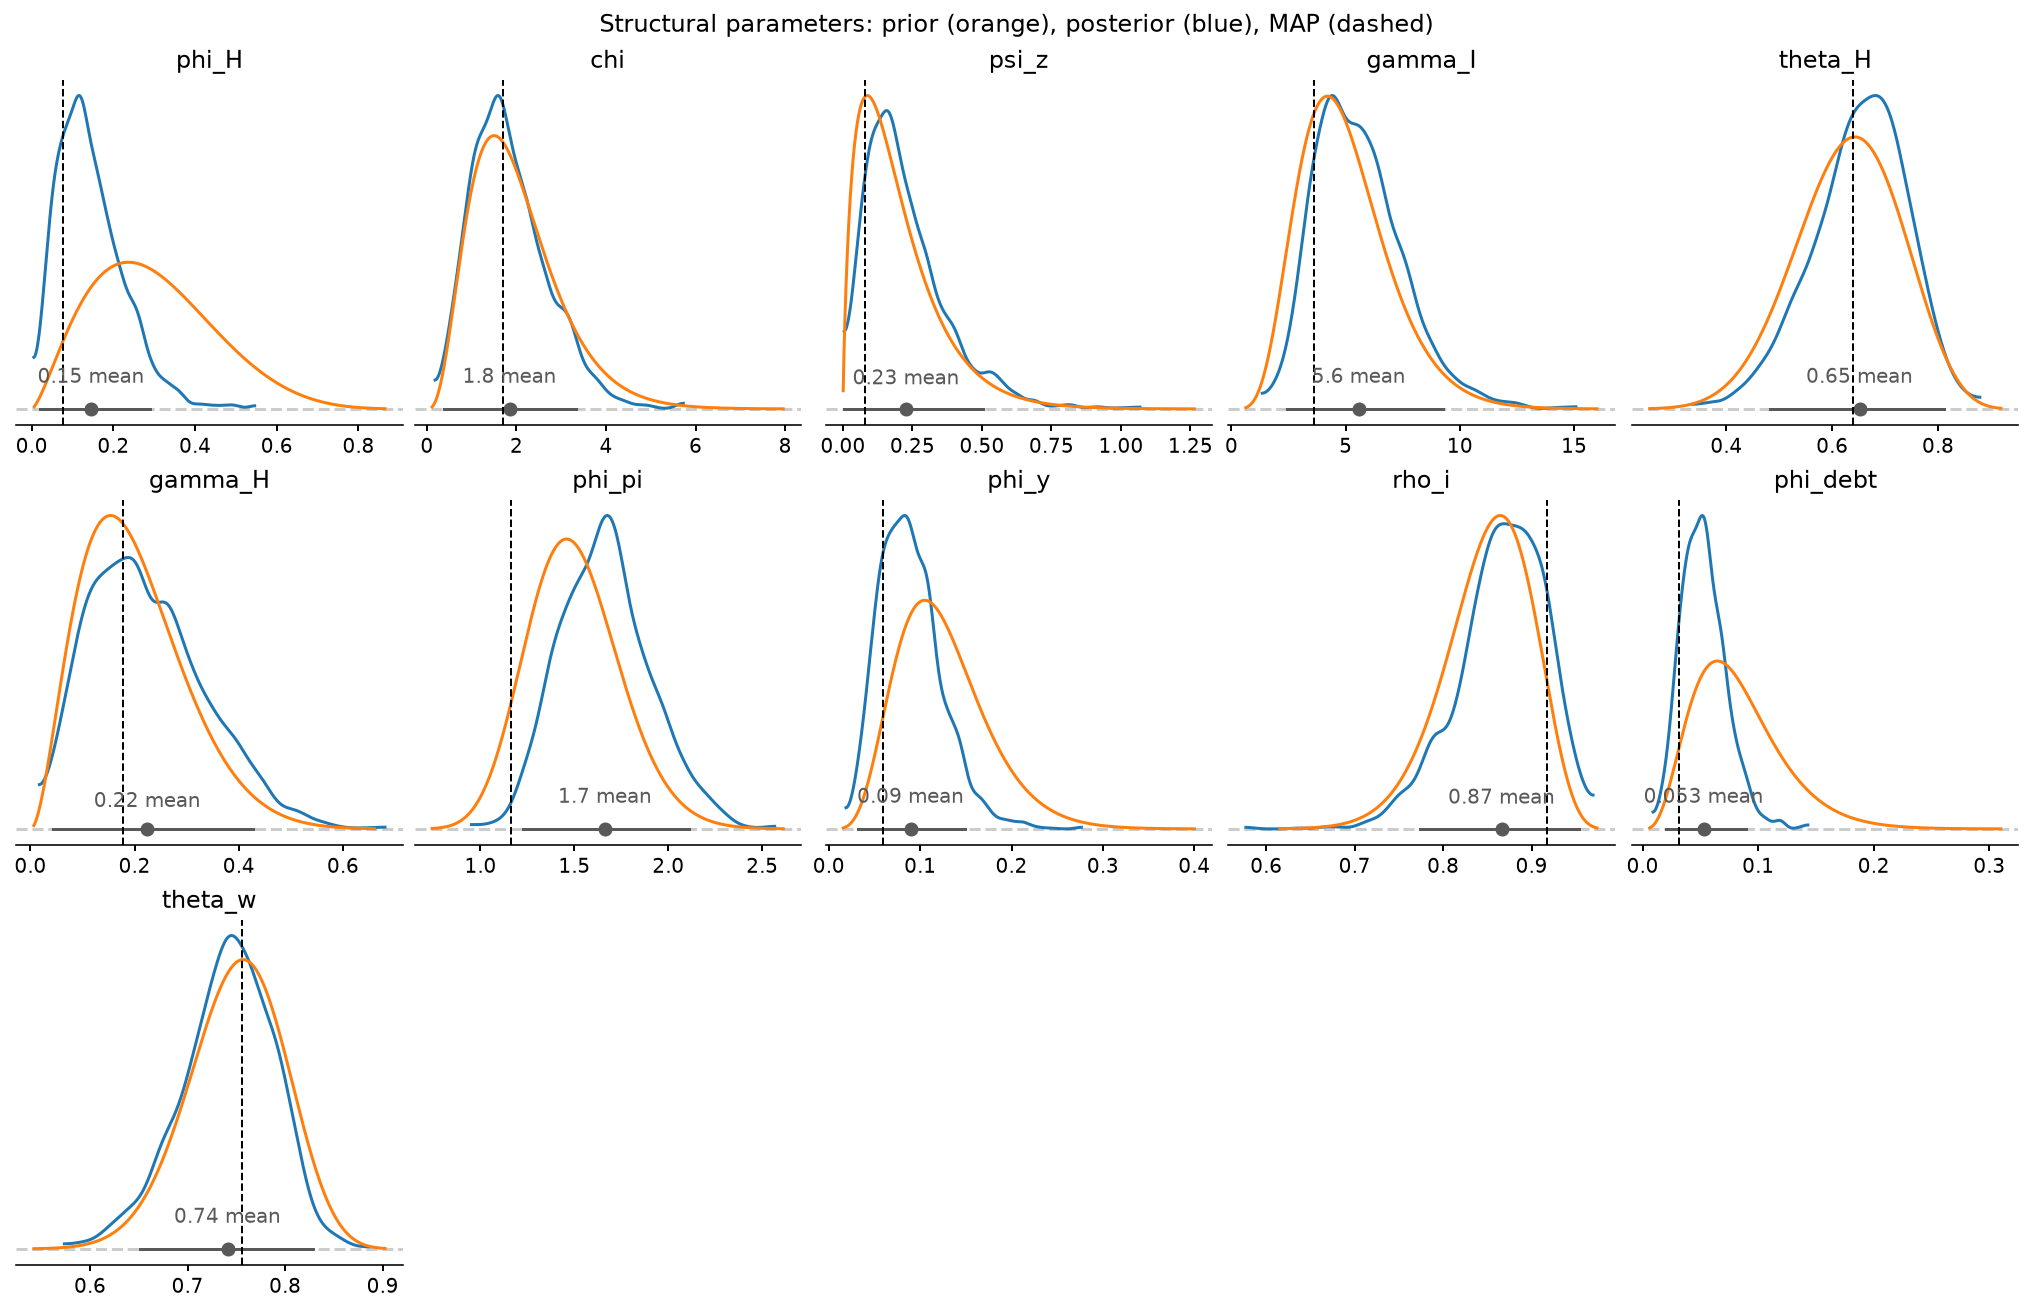

In [15]:
fig = plot_posterior_with_prior(map_init_idata,
                                var_names=ESTIMATED_STRUCTURAL,
                                prior_dict=preliz_priors,
                                true_values=map_estimate)
fig.suptitle("Structural parameters: prior (orange), posterior (blue), MAP (dashed)");

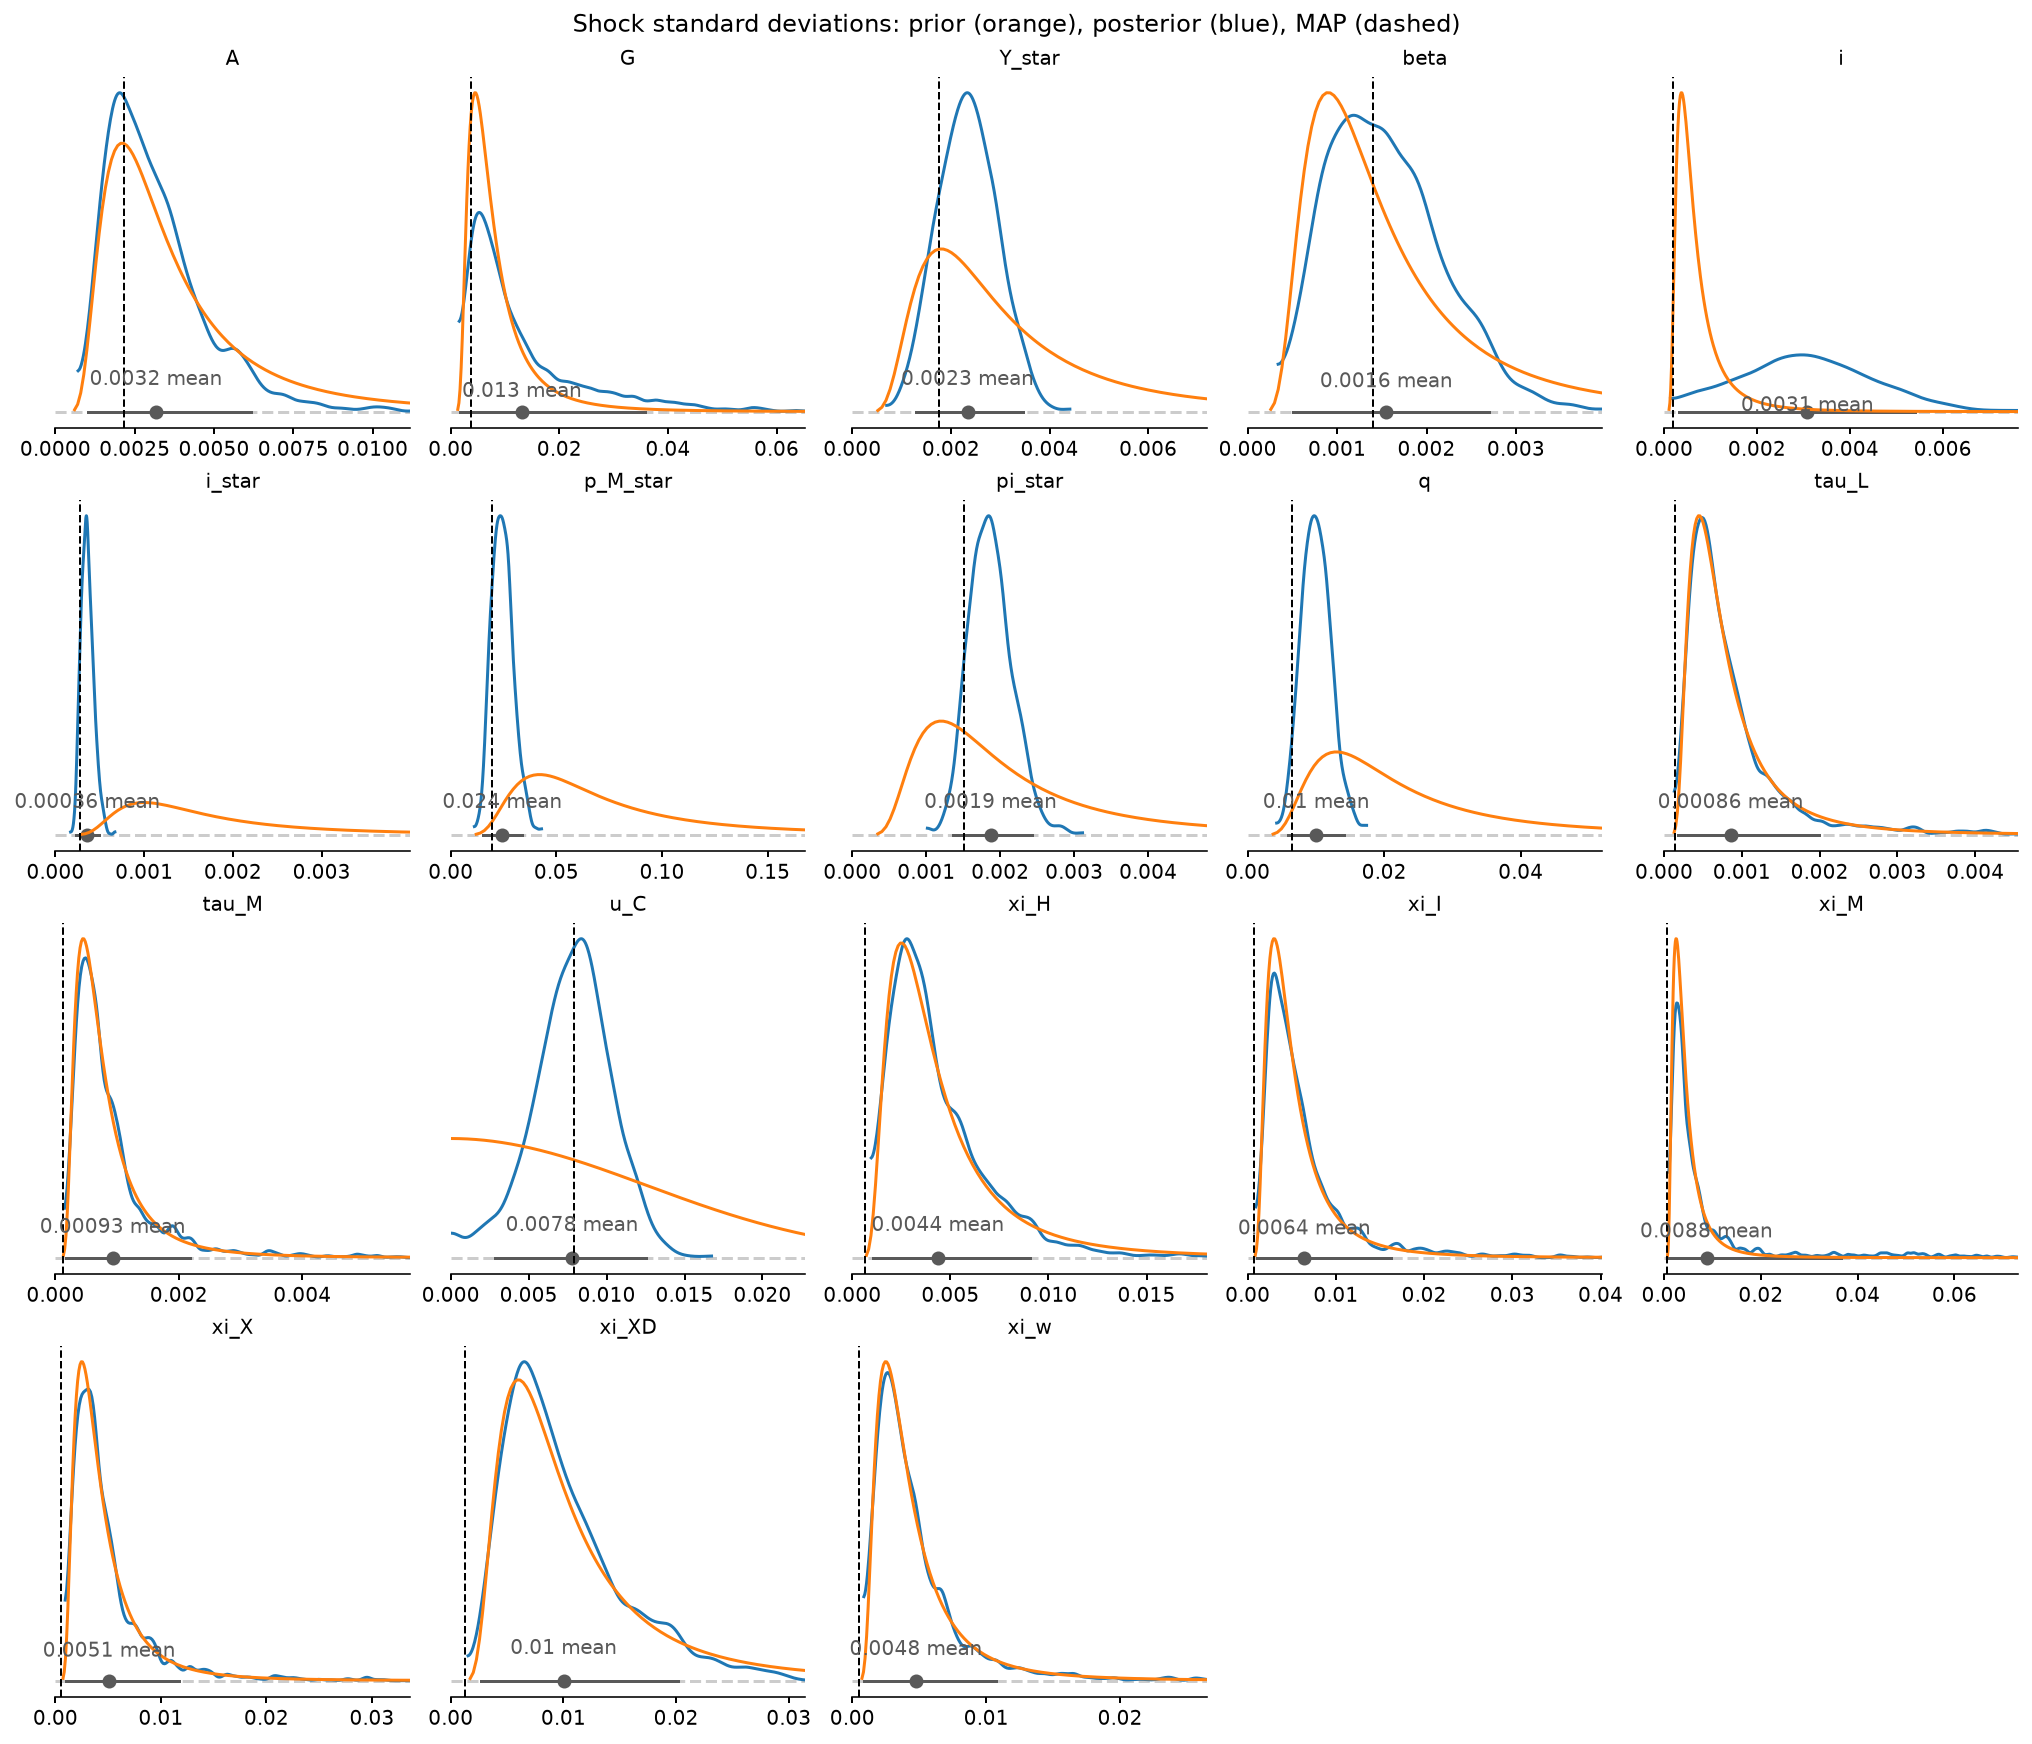

In [16]:
fig = plot_posterior_with_prior(map_init_idata,
                                var_names=SHOCK_SIGMA_NAMES,
                                prior_dict=preliz_priors,
                                true_values=map_estimate,
                                n_cols=5)

posterior_upper = map_init_idata.posterior.to_dataset()[SHOCK_SIGMA_NAMES].quantile(0.995)
for axis in fig.axes:
    name = axis.get_title()
    if name not in SHOCK_SIGMA_NAMES:
        continue
    upper = max(float(posterior_upper[name]), preliz_priors[name].ppf(0.9), float(map_estimate[name]))
    axis.set_xlim(0, 1.1 * upper)
    axis.set_title(name.removeprefix("sigma_epsilon_"), fontsize=10)

fig.suptitle("Shock standard deviations: prior (orange), posterior (blue), MAP (dashed)");

Sampling: [error_share_logit_mean, error_share_offset, error_share_spread]


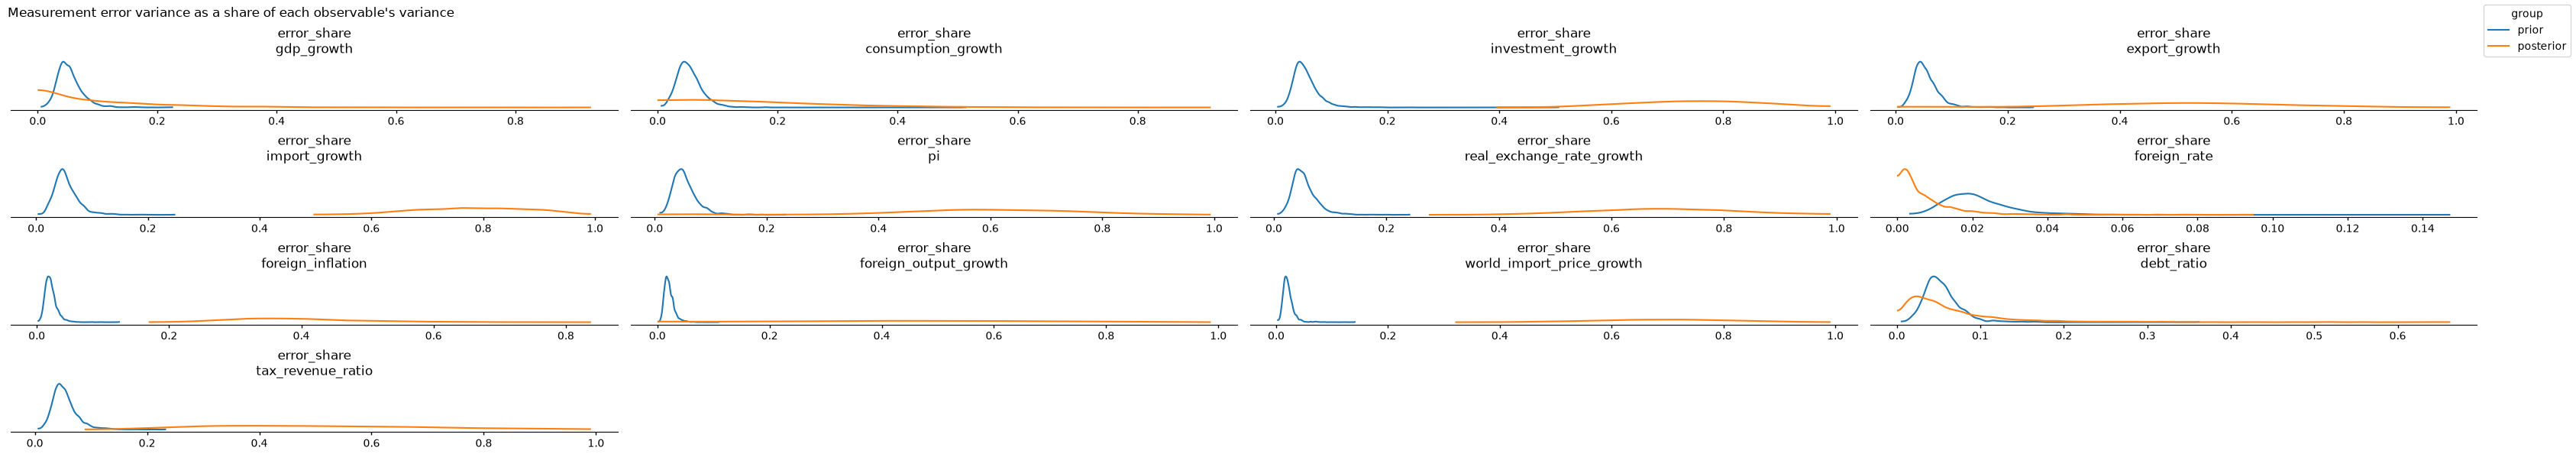

In [17]:
with pymc_model:
    error_share_prior = pm.sample_prior_predictive(draws=2000,
                                                   var_names=["error_share"],
                                                   random_seed=20261014)

error_share_trees = xr.DataTree.from_dict({"prior": error_share_prior["prior"].to_dataset(),
                                           "posterior": map_init_idata["posterior"].to_dataset()[["error_share"]]})
plot_collection = az.plot_prior_posterior(error_share_trees, var_names=["error_share"])
plot_collection.viz["figure"].item().suptitle("Measurement error variance as a share of each observable's variance",
                                              x=0.0,
                                              ha="left");

## 6. DSGE checks

Properties of the solved model across all posterior draws: stability of the linear solution, the autocorrelations and correlations it implies for the observables, and the steady-state great ratios.

In [18]:
posterior_draws = map_init_idata.posterior.to_dataset()
solved = posterior_draws["deterministic_norm"] <= 1e-6
chain_draw_pairs = list(product(posterior_draws["chain"].values, posterior_draws["draw"].values))
parameters_by_draw = {(chain, draw): {**india_parameters,
                                      **{name: float(posterior_draws[name].sel(chain=chain, draw=draw))
                                         for name in ESTIMATED_STRUCTURAL}}
                      for chain, draw in chain_draw_pairs}

observed_data = xr.Dataset({"obs": (("time", "observed_state"), fit_data.to_numpy())},
                           coords={"time": fit_data.index.rename("time"),
                                   "observed_state": fit_data.columns})
statespace_idata = statespace_trace(draws=posterior_draws,
                                    parameter_values=fixed_parameters(statespace, india_model_parameters),
                                    observed_data=observed_data,
                                    group="posterior")

### Solver convergence

Cycle reduction inside the likelihood stops after 50 iterations whether or not it has converged. The deterministic norm is the residual of the matrix quadratic at the returned solution.

In [19]:
solver_trace = posterior_draws[["n_cycle_steps", "deterministic_norm"]].to_dataframe()
solver_trace["unsolved"] = ~solved.to_series()
solver_trace["diverging"] = map_init_idata.sample_stats["diverging"].to_series()

display(solver_trace[["n_cycle_steps", "deterministic_norm"]].describe(percentiles=[0.5, 0.99]).T.style.format("{:.3g}"))
pd.crosstab(index=solver_trace["unsolved"],
            columns=solver_trace["diverging"],
            margins=True)

,count,mean,std,min,50%,99%,max
n_cycle_steps,2e+03,10.1,0.256,10,10,11,13
deterministic_norm,2e+03,0.000192,0.00726,2.8e-13,2.48e-11,2.46e-07,0.323


diverging,False,True,All
unsolved,,,
False,1956,30,1986
True,6,8,14
All,1962,38,2000


### Stability

Generalized eigenvalues of the linearized system at each posterior draw. Stable roots lie inside the unit circle.

posterior draws:   0%|          | 0/2000 [00:00<?, ?it/s]

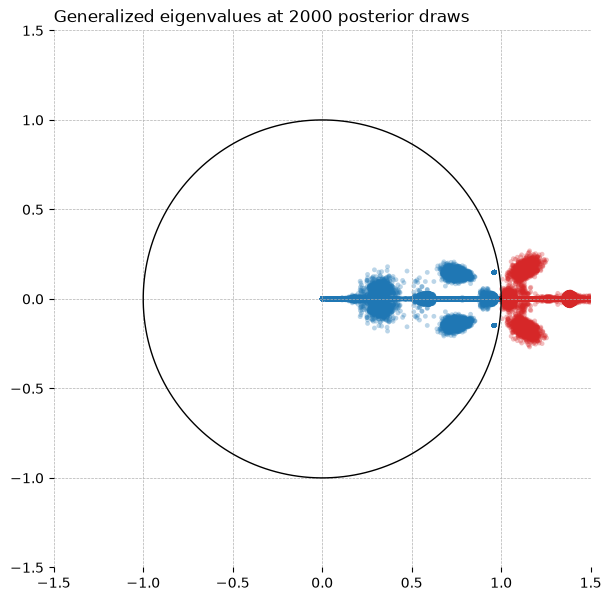

In [20]:
fig, ax = plt.subplots(figsize=(6, 6), layout="constrained")
for chain, draw in tqdm(chain_draw_pairs, desc="posterior draws"):
    plot_eigenvalues(model,
                     fig=fig,
                     plot_circle=(chain == 0 and draw == 0),
                     linearize_model_kwargs={"verbose": False},
                     **parameters_by_draw[chain, draw])

for collection in ax.collections:
    collection.set(alpha=0.3,
                   sizes=[12],
                   linewidths=0)

ax.set(xlim=(-1.5, 1.5),
       ylim=(-1.5, 1.5))
ax.set_title("")
ax.set_title(f"Generalized eigenvalues at {len(chain_draw_pairs)} posterior draws", loc="left");

### Moments of the observables

Each posterior draw simulates the observables over 2012Q1 to 2024Q4 from the stationary distribution, with measurement error, and the lockdown quarters are dropped as in the data. The simulated sample moments of the quarterly observables are compared against the same moments of the data, so the intervals include the sampling variability of a 44-quarter sample. Draws whose solution did not converge are excluded.

In [21]:
ACF_LAGS = 8
QUARTERLY_OBSERVABLES = ["gdp_growth",
                         "consumption_growth",
                         "investment_growth",
                         "export_growth",
                         "import_growth",
                         "pi",
                         "real_exchange_rate_growth",
                         "foreign_rate",
                         "foreign_inflation",
                         "foreign_output_growth",
                         "world_import_price_growth"]

posterior_predictive = statespace.sample_unconditional_posterior(statespace_idata,
                                                                use_data_time_dim=True,
                                                                random_seed=20261014)
simulated = (posterior_predictive["posterior_observed"]
             .where(solved)
             .stack(sample=["chain", "draw"])
             .dropna("sample", how="all")
             .drop_vars(["sample", "chain", "draw"])
             .sel(observed_state=QUARTERLY_OBSERVABLES)
             .rename(observed_state="variable"))
missing_in_data = xr.DataArray(fit_data.isna().all(axis=1).to_numpy(),
                               dims=["time"],
                               coords={"time": simulated["time"]})
simulated = simulated.where(~missing_in_data)
data = xr.DataArray(fit_data[QUARTERLY_OBSERVABLES].to_numpy(),
                    dims=["time", "variable"],
                    coords={"time": simulated["time"], "variable": QUARTERLY_OBSERVABLES})


def lagged_correlation(values, lag):
    """Correlation of each variable at t with each variable_aux at t - lag, over quarters where both are observed."""
    return xr.corr(values,
                   values.shift(time=lag).rename(variable="variable_aux"),
                   dim="time")


def sample_moments(values):
    autocorrelation = xr.concat([lagged_correlation(values, lag) for lag in range(ACF_LAGS)], dim="lag")
    return xr.Dataset({"std": values.std("time", ddof=1),
                       "acf": autocorrelation.transpose(..., "lag", "variable", "variable_aux")},
                      coords={"lag": np.arange(ACF_LAGS)})


predictive_moments = sample_moments(simulated)
data_moments = sample_moments(data)
pd.Series({"posterior draws": solver_trace.shape[0],
           "simulated (solved draws)": predictive_moments.sizes["sample"],
           "quarters per simulation": simulated.sizes["time"],
           "observed quarters per simulation": int(simulated.isel(sample=0, variable=0).notnull().sum())},
          name="count").to_frame()

/Users/jessegrabowski/mambaforge/envs/climate-risk/lib/python3.12/site-packages/pytensor/link/jax/linker.py:50: UserWarning: The RandomType SharedVariables [RNG(Generator(PCG64))] will not be used in the compiled JAX graph. Instead a copy will be used.
  warnings.warn(
Sampling: [posterior_combined]


Output()

,count
posterior draws,2000
simulated (solved draws),1986
quarters per simulation,52
observed quarters per simulation,44


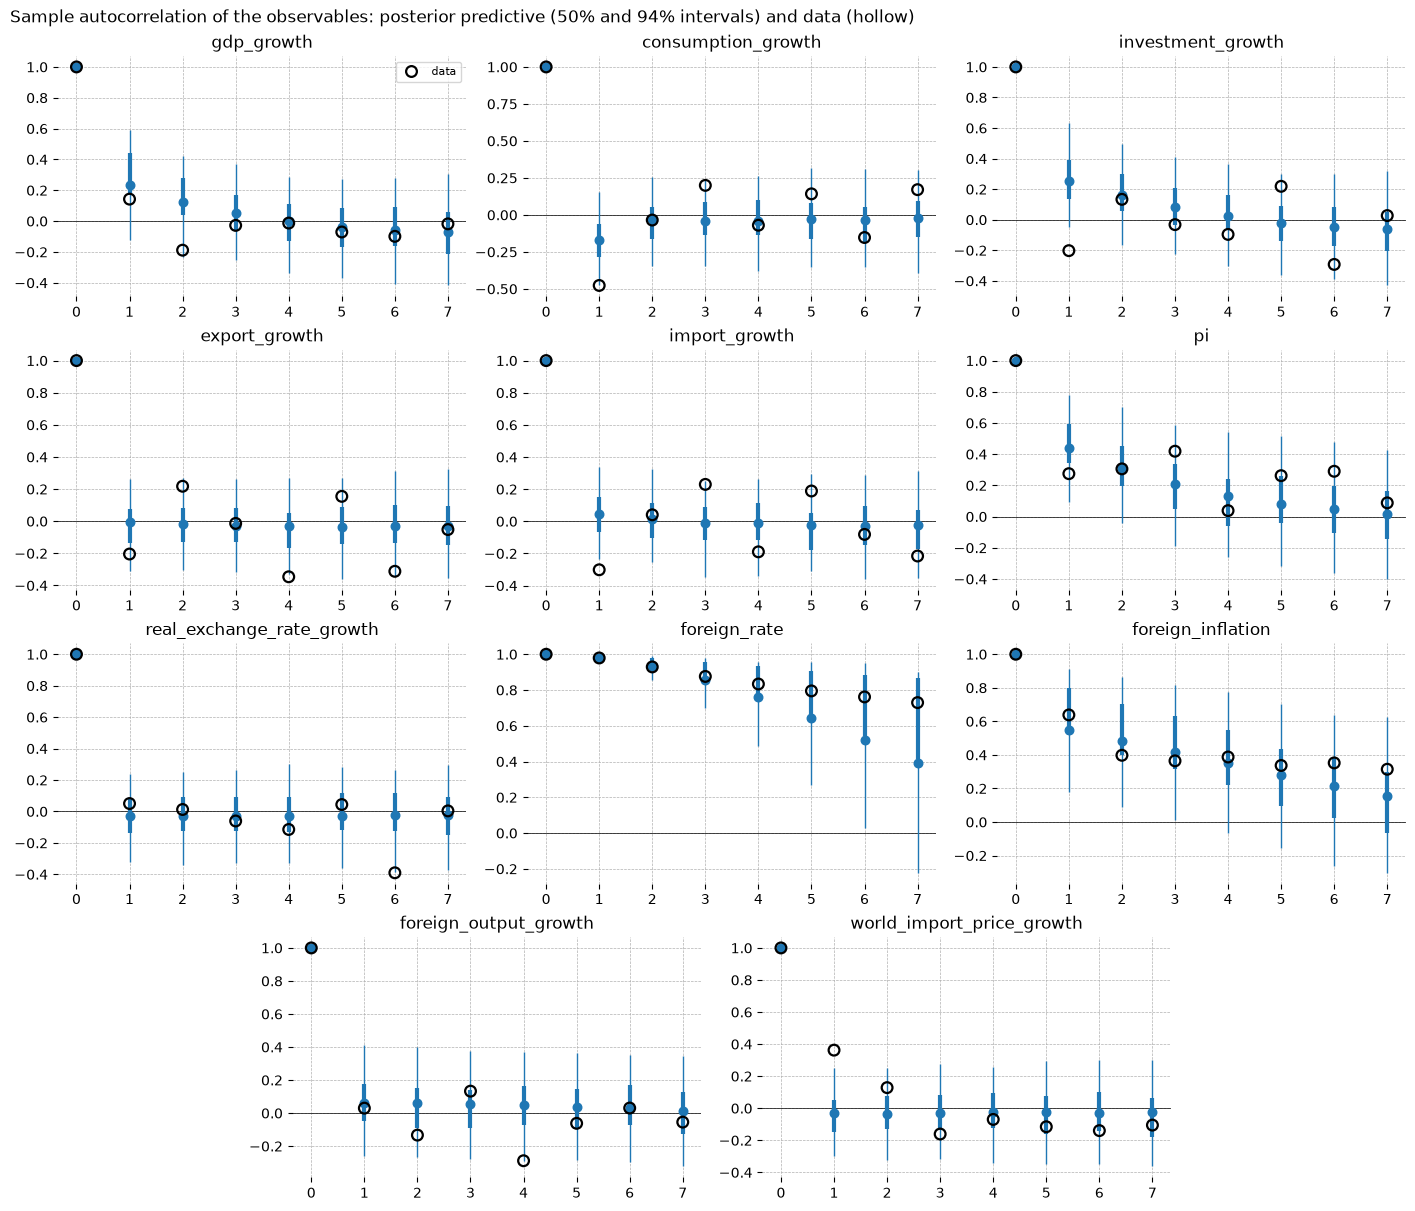

In [22]:
data_autocorrelation = data_moments["acf"].sel(variable_aux=data_moments["variable"]).drop_vars("variable_aux")

fig = plot_acf(predictive_moments["acf"].rename(sample="draw").expand_dims(chain=[0]),
               reference=data_autocorrelation,
               figsize=(14, 12),
               n_cols=3)
fig.suptitle("Sample autocorrelation of the observables: posterior predictive (50% and 94% intervals) and data (hollow)",
             x=0.0,
             ha="left");

The diagonal shows posterior predictive densities of each observable's sample standard deviation, and the dashed line marks the data. Below the diagonal, each panel shows the posterior predictive median (dot) with 50% (thick) and 94% (thin) intervals for one sample correlation, and the hollow marker is the data.

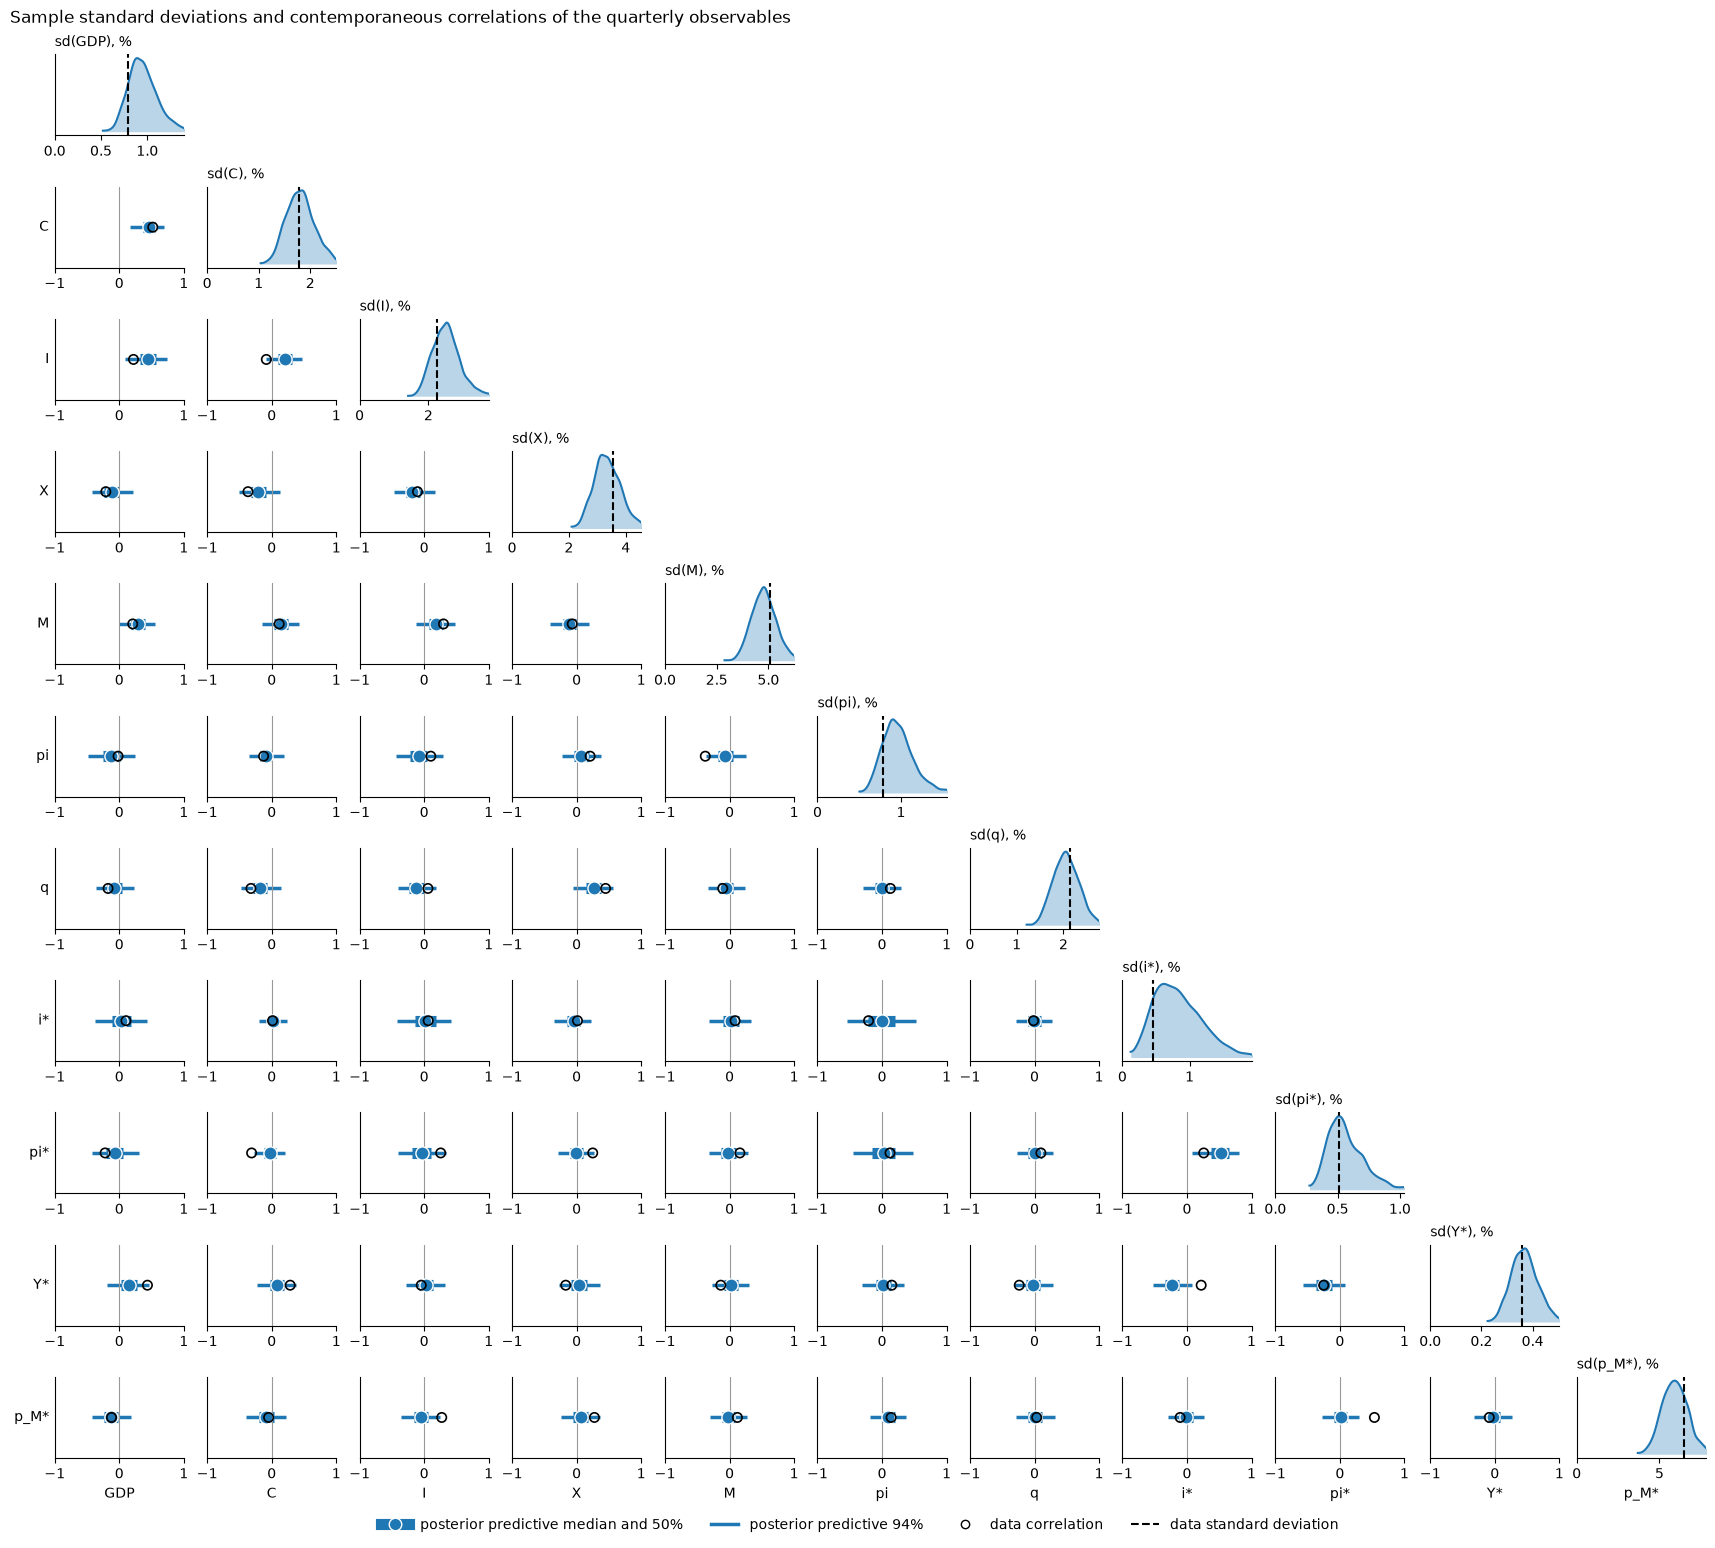

In [23]:
fig = plot_moment_grid(predictive_moments=predictive_moments,
                       data_moments=data_moments,
                       label="posterior predictive")
fig.suptitle("Sample standard deviations and contemporaneous correlations of the quarterly observables",
             x=0.0,
             ha="left");

### Great ratios across the posterior

Posterior densities of the steady-state expenditure and income shares, with the 2012 to 2024 averages of `02_catdsge_prior_analysis.ipynb` dashed. Only the estimated parameters move across draws. A vertical line in place of a density marks a ratio those parameters do not affect.

In [24]:
posterior_ratios = pd.DataFrame([model_ratios(model, **parameters_by_draw[chain, draw])
                                 for chain, draw in tqdm(chain_draw_pairs, desc="posterior draws")])

posterior draws:   0%|          | 0/2000 [00:00<?, ?it/s]

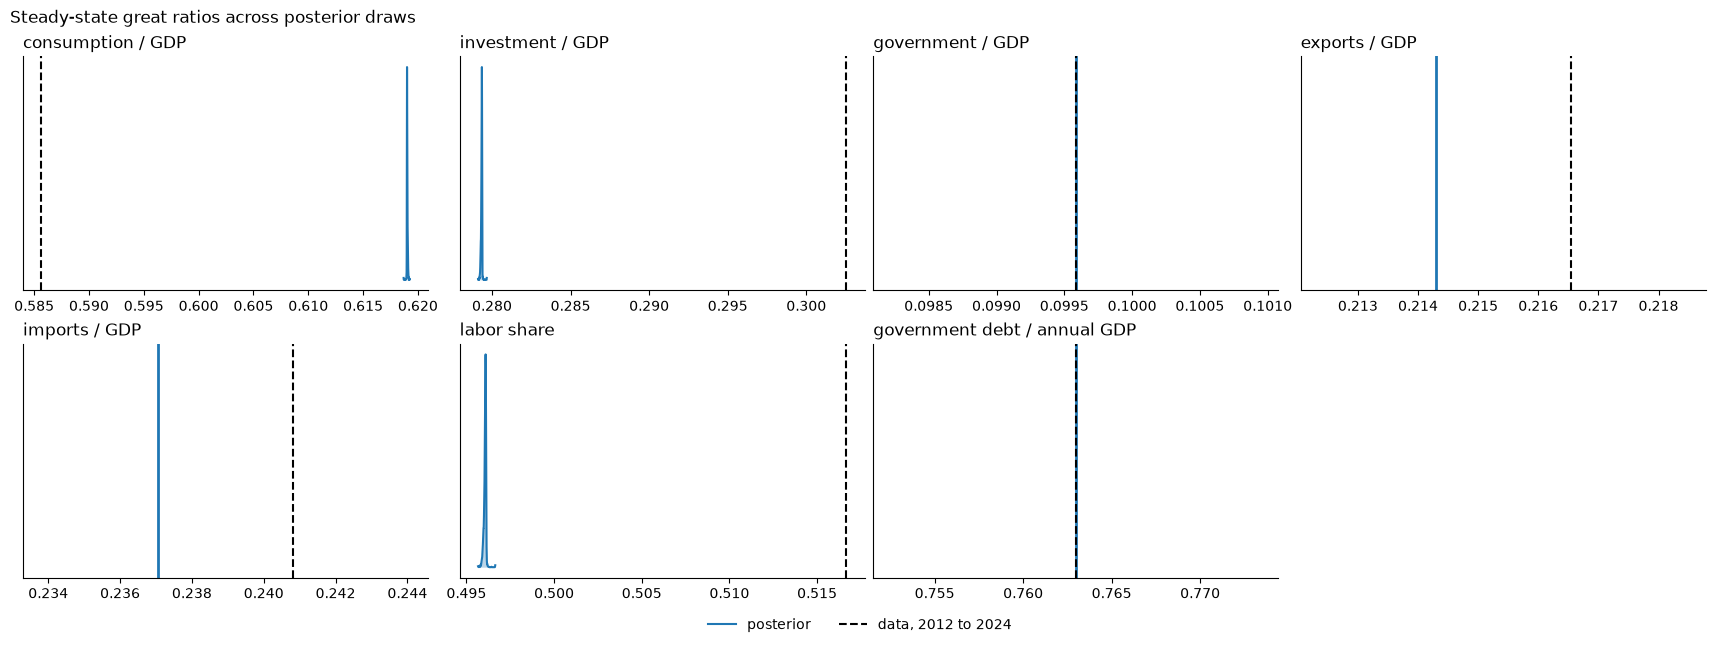

In [25]:
fig, axes = plt.subplots(nrows=2,
                         ncols=4,
                         figsize=(17, 6),
                         layout="constrained")
for ax, ratio in zip(axes.flat, posterior_ratios.columns):
    plot_density_against_data(ax=ax,
                              values=posterior_ratios[ratio],
                              data_value=data_targets[ratio])
    ax.set_title(ratio, loc="left")
axes.flat[-1].set_axis_off()

legend_handles = [plt.Line2D([], [], color=PALETTE["primary"], lw=1.5, label="posterior"),
                  plt.Line2D([], [], color="k", ls="--", lw=1.5, label="data, 2012 to 2024")]
fig.legend(handles=legend_handles,
           loc="upper center",
           bbox_to_anchor=(0.5, 0.0),
           ncol=len(legend_handles),
           frameon=False)
fig.suptitle("Steady-state great ratios across posterior draws", x=0.0, ha="left");

### Smoothed states and shocks

The Kalman smoother's estimates of the observables, the unobserved states and the structural shocks over the sample, given all of the data, with bands across posterior draws. A smoothed observable is the model's signal $d + Z x_t$ without measurement error, so its gap to the data is the measurement error. The shocks are backed out of the transition equation from each draw's smoothed state means and divided by their estimated standard deviations. A well-specified model gives shock series centered on zero, mostly inside two standard deviations and without persistent runs.

In [26]:
# The Kalman filter samplers read the data from constant_data.
filter_idata = xr.DataTree.from_dict({"posterior": statespace_idata["posterior"].to_dataset(),
                                      "observed_data": observed_data,
                                      "constant_data": xr.Dataset({"data": observed_data["obs"]})})
conditional_posterior = statespace.sample_conditional_posterior(filter_idata, random_seed=20261014)
smoothed_states = statespace.sample_filter_outputs(filter_idata,
                                                   filter_output_names="smoothed_states",
                                                   random_seed=20261014)["posterior_predictive"]["smoothed_states"]
statespace_matrices = statespace.sample_statespace_matrices(filter_idata,
                                                            matrix_names=["c", "d", "T", "Z", "R"],
                                                            random_seed=20261014)["posterior_predictive"]

lagged_states = smoothed_states.shift(time=1).rename(state="state_aux")
transition_residual = (smoothed_states
                       - statespace_matrices["c"]
                       - xr.dot(statespace_matrices["T"], lagged_states, dim="state_aux"))
selection_inverse = xr.apply_ufunc(np.linalg.pinv,
                                   statespace_matrices["R"],
                                   input_core_dims=[["state", "shock"]],
                                   output_core_dims=[["shock", "state"]])
shock_sd = xr.concat([posterior_draws[f"sigma_{shock}"] for shock in estimated_shocks],
                     dim=pd.Index(estimated_shocks, name="shock"))
standardized_shocks = (xr.dot(selection_inverse, transition_residual, dim="state") / shock_sd).isel(time=slice(1, None))

/Users/jessegrabowski/mambaforge/envs/climate-risk/lib/python3.12/site-packages/pytensor/link/jax/linker.py:50: UserWarning: The RandomType SharedVariables [RNG(Generator(PCG64)), RNG(Generator(PCG64)), RNG(Generator(PCG64)), RNG(Generator(PCG64)), RNG(Generator(PCG64)), RNG(Generator(PCG64))] will not be used in the compiled JAX graph. Instead a copy will be used.
  warnings.warn(
Sampling: [filtered_posterior, filtered_posterior_observed, predicted_posterior, predicted_posterior_observed, smoothed_posterior, smoothed_posterior_observed]


Output()

Sampling: []


Output()

Sampling: []


Output()

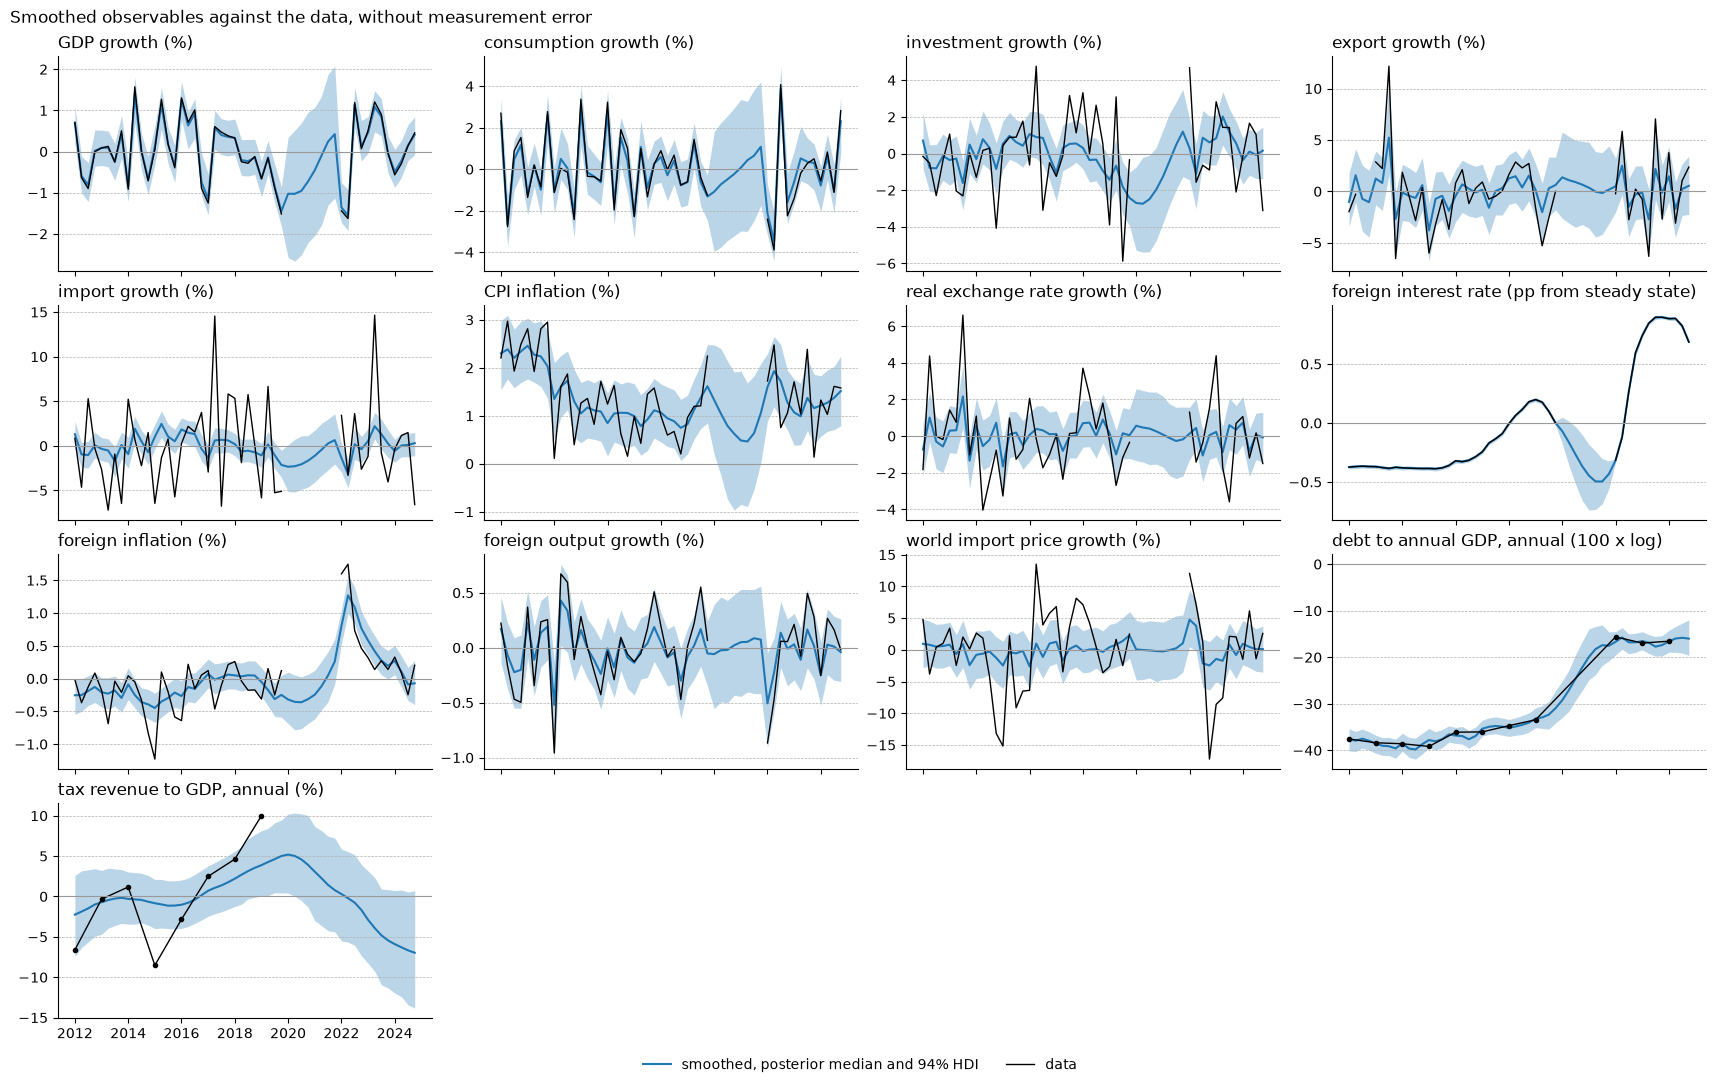

In [27]:
OBSERVABLE_TITLES = {"gdp_growth": "GDP growth (%)",
                     "consumption_growth": "consumption growth (%)",
                     "investment_growth": "investment growth (%)",
                     "export_growth": "export growth (%)",
                     "import_growth": "import growth (%)",
                     "pi": "CPI inflation (%)",
                     "real_exchange_rate_growth": "real exchange rate growth (%)",
                     "foreign_rate": "foreign interest rate (pp from steady state)",
                     "foreign_inflation": "foreign inflation (%)",
                     "foreign_output_growth": "foreign output growth (%)",
                     "world_import_price_growth": "world import price growth (%)",
                     "debt_ratio": "debt to annual GDP, annual (100 x log)",
                     "tax_revenue_ratio": "tax revenue to GDP, annual (%)"}
ANNUAL_OBSERVABLES = ["debt_ratio", "tax_revenue_ratio"]
SMOOTHED_LABEL = "smoothed, posterior median and 94% HDI"


def plot_smoothed_panels(paths, titles, data=None, reference_levels=(0.0,), n_cols=4):
    """One panel per entry of `titles`, each a smoothed path over time with the data drawn on top if given."""
    n_rows = int(np.ceil(len(titles) / n_cols))
    fig, axes = plt.subplots(nrows=n_rows,
                             ncols=n_cols,
                             figsize=(17, 2.6 * n_rows),
                             sharex=True,
                             layout="constrained")
    dates = paths["time"].to_numpy()
    for ax, (name, title) in zip(axes.flat, titles.items()):
        median, interval = median_and_hdi(paths.sel(variable=name))
        ax.fill_between(dates,
                        interval.sel(ci_bound="lower"),
                        interval.sel(ci_bound="upper"),
                        color=PALETTE["primary"],
                        alpha=0.3,
                        linewidth=0)
        ax.plot(dates,
                median,
                color=PALETTE["primary"],
                lw=1.5,
                label=SMOOTHED_LABEL)
        if data is not None:
            series = data[name].dropna() if name in ANNUAL_OBSERVABLES else data[name]
            ax.plot(series.index,
                    series,
                    color="k",
                    lw=1.0,
                    marker="o" if name in ANNUAL_OBSERVABLES else None,
                    markersize=3,
                    label="data")
        for level in reference_levels:
            ax.axhline(level, color="0.6", lw=0.8, ls="-" if level == 0 else ":")
        ax.set_title(title, loc="left")
    for ax in axes.flat[len(titles):]:
        ax.set_axis_off()

    handles, labels = axes.flat[0].get_legend_handles_labels()
    fig.legend(handles=handles,
               labels=labels,
               loc="upper center",
               bbox_to_anchor=(0.5, 0.0),
               ncol=len(labels),
               frameon=False)
    return fig, axes


smoothed_signal = statespace_matrices["d"] + xr.dot(statespace_matrices["Z"],
                                                    conditional_posterior["smoothed_posterior"],
                                                    dim="state")
smoothed_observed = 100 * smoothed_signal.sel(observed_state=list(OBSERVABLE_TITLES)).rename(observed_state="variable")
fig, axes = plot_smoothed_panels(paths=smoothed_observed,
                                 titles=OBSERVABLE_TITLES,
                                 data=100 * fit_data)
fig.suptitle("Smoothed observables against the data, without measurement error", x=0.0, ha="left");

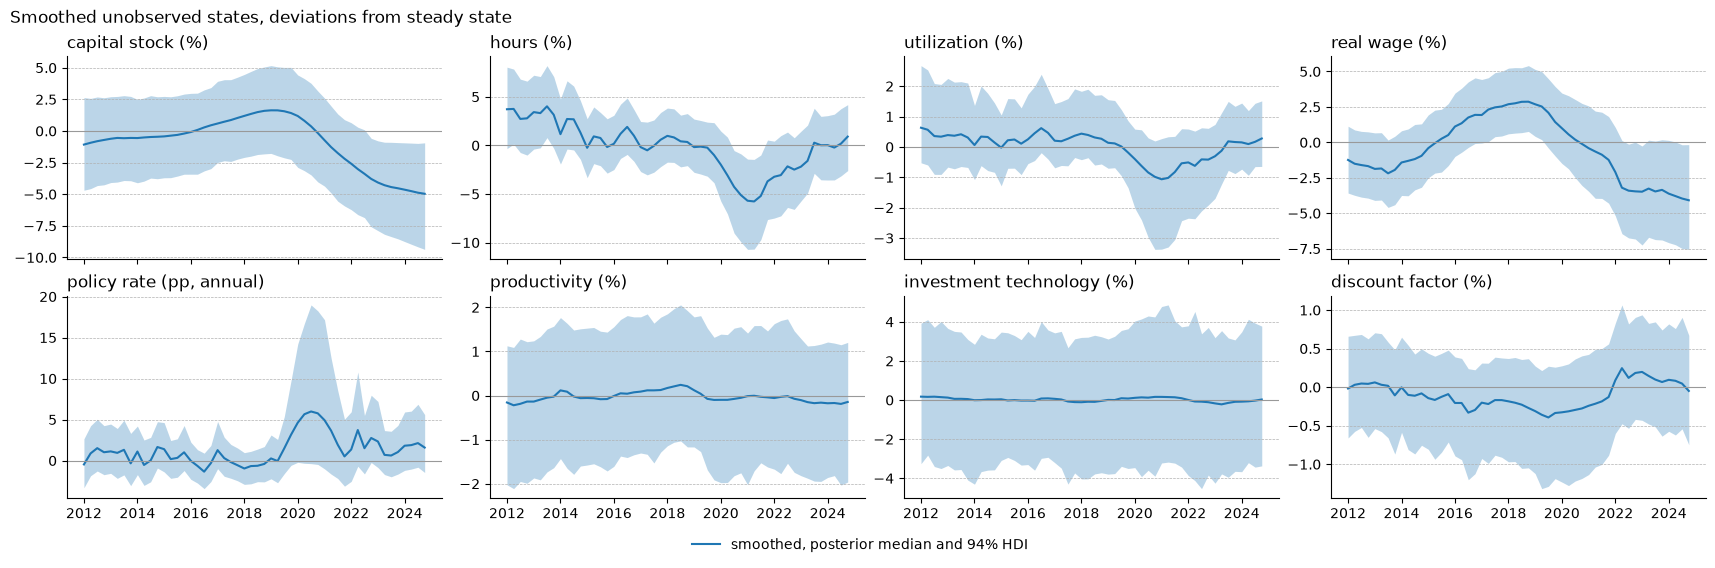

In [28]:
HIDDEN_STATE_TITLES = {"K": "capital stock (%)",
                       "L": "hours (%)",
                       "z": "utilization (%)",
                       "w": "real wage (%)",
                       "i": "policy rate (pp, annual)",
                       "A": "productivity (%)",
                       "xi_I": "investment technology (%)",
                       "beta": "discount factor (%)"}

smoothed_latent = conditional_posterior["smoothed_posterior"].rename(state="variable")
smoothed_hidden = xr.concat([to_display_units(irf=smoothed_latent,
                                              variable=name,
                                              policy_rate_ss=india_steady_state["i_ss"])
                             for name in HIDDEN_STATE_TITLES],
                            dim=pd.Index(list(HIDDEN_STATE_TITLES), name="variable"))
fig, axes = plot_smoothed_panels(paths=smoothed_hidden,
                                 titles=HIDDEN_STATE_TITLES)
fig.suptitle("Smoothed unobserved states, deviations from steady state", x=0.0, ha="left");

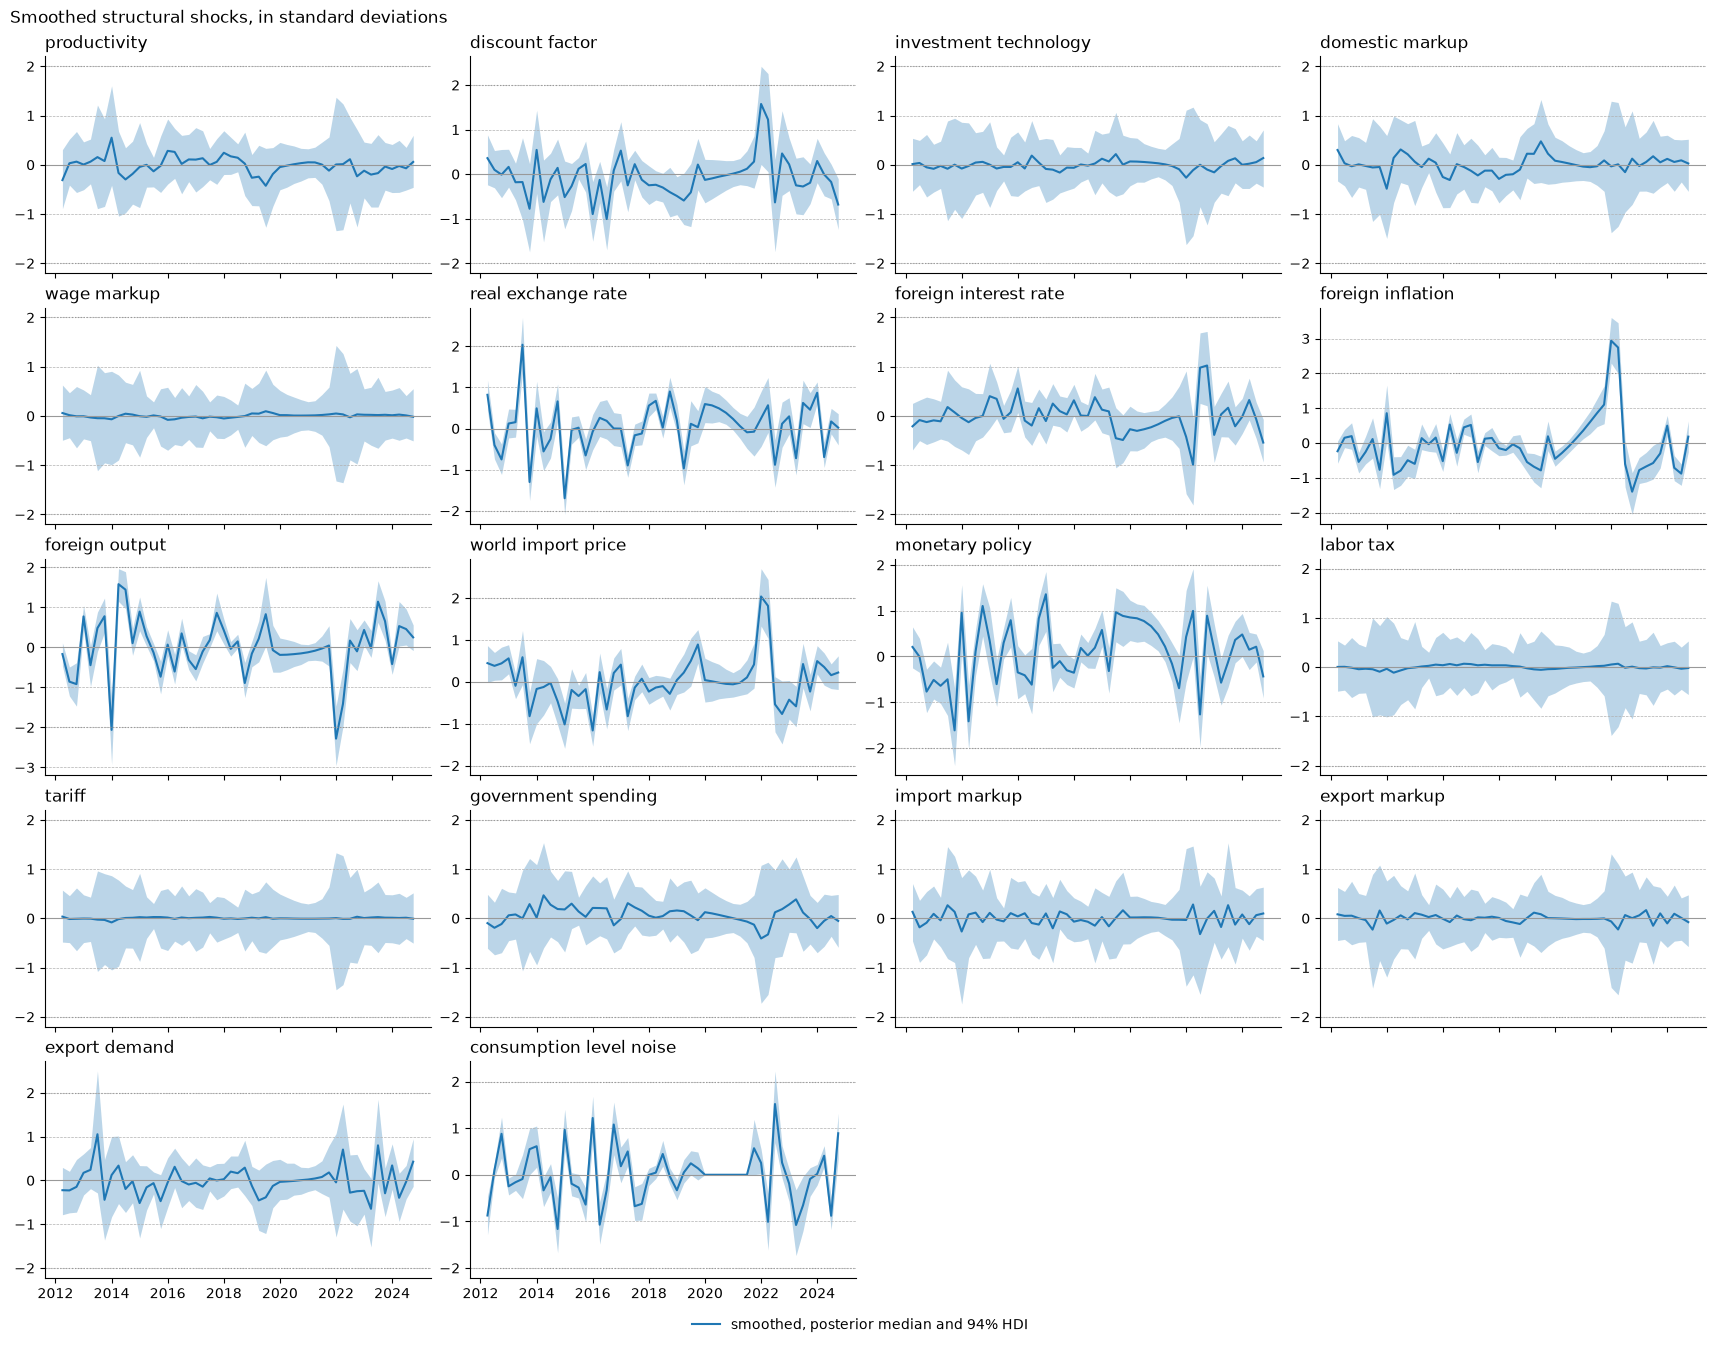

In [29]:
SHOCK_TITLES = {"epsilon_A": "productivity",
                "epsilon_beta": "discount factor",
                "epsilon_xi_I": "investment technology",
                "epsilon_xi_H": "domestic markup",
                "epsilon_xi_w": "wage markup",
                "epsilon_q": "real exchange rate",
                "epsilon_i_star": "foreign interest rate",
                "epsilon_pi_star": "foreign inflation",
                "epsilon_Y_star": "foreign output",
                "epsilon_p_M_star": "world import price",
                "epsilon_i": "monetary policy",
                "epsilon_tau_L": "labor tax",
                "epsilon_tau_M": "tariff",
                "epsilon_G": "government spending",
                "epsilon_xi_M": "import markup",
                "epsilon_xi_X": "export markup",
                "epsilon_xi_XD": "export demand",
                "epsilon_u_C": "consumption level noise"}

fig, axes = plot_smoothed_panels(paths=standardized_shocks.rename(shock="variable"),
                                 titles=SHOCK_TITLES,
                                 reference_levels=(-2.0, 0.0, 2.0))
fig.suptitle("Smoothed structural shocks, in standard deviations", x=0.0, ha="left");